In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'
PURPLE = '#8E44AD'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


In [ ]:
retail = pd.read_parquet('online_retail_clean.parquet')
retail['InvoiceDate']  = pd.to_datetime(retail['InvoiceDate'])
retail['InvoiceMonth'] = retail['InvoiceDate'].dt.to_period('M')

df = pd.read_csv('telco_clean.csv')

print(f"Online Retail  : {len(retail):,} transactions, {retail['Customer ID'].nunique():,} customers")
print(f"Telco (Churn)  : {len(df):,} subscribers")


Online Retail  : 805,549 transactions, 5,878 customers
Telco (Churn)  : 7,043 subscribers


In [ ]:
months         = sorted(retail['InvoiceMonth'].unique())
ever_customers = set()   # accumulates all customers seen so far
prev_customers = set()
prev_rev       = pd.Series(dtype=float)

mrr_rows = []

for month in months:
    current     = retail[retail['InvoiceMonth'] == month]
    curr_custs  = set(current['Customer ID'].unique())
    curr_rev    = current.groupby('Customer ID')['Revenue'].sum()

    # Classify each customer this month
    new_custs         = curr_custs - ever_customers
    returning_custs   = curr_custs & prev_customers
    reactivated_custs = curr_custs & (ever_customers - prev_customers)
    churned_custs     = prev_customers - curr_custs

    new_rev         = curr_rev[curr_rev.index.isin(new_custs)].sum()
    returning_rev   = curr_rev[curr_rev.index.isin(returning_custs)].sum()
    reactivated_rev = curr_rev[curr_rev.index.isin(reactivated_custs)].sum()
    churned_rev     = prev_rev[prev_rev.index.isin(churned_custs)].sum() if len(prev_rev) else 0

    mrr_rows.append({
        'Month'          : str(month),
        'New MRR'        : new_rev,
        'Returning MRR'  : returning_rev,
        'Reactivated MRR': reactivated_rev,
        'Churned MRR'    : -churned_rev,   # shown as negative — it is revenue lost
        'Total Revenue'  : curr_rev.sum(),
        'Active Customers': len(curr_custs),
    })

    ever_customers |= curr_custs   # add this month to the all-time set
    prev_customers  = curr_custs
    prev_rev        = curr_rev

mrr_df = pd.DataFrame(mrr_rows)

print("MRR movement table (first 5 months):")
print(mrr_df.head().to_string())
print(f"\nColumns: {list(mrr_df.columns)}")


MRR movement table (first 5 months):
     Month     New MRR  Returning MRR  Reactivated MRR  Churned MRR  Total Revenue  Active Customers
0  2009-12  686654.160          0.000             0.00        0.000     686654.160               955
1  2010-01  161893.491     395425.571             0.00  -275382.160     557319.062               720
2  2010-02  170434.884     266277.472         69658.71  -195031.942     506371.066               772
3  2010-03  235467.061     317617.240        146524.69  -211997.714     699608.991              1057
4  2010-04  125100.731     315656.861        153851.60  -323795.261     594609.192               942

Columns: ['Month', 'New MRR', 'Returning MRR', 'Reactivated MRR', 'Churned MRR', 'Total Revenue', 'Active Customers']


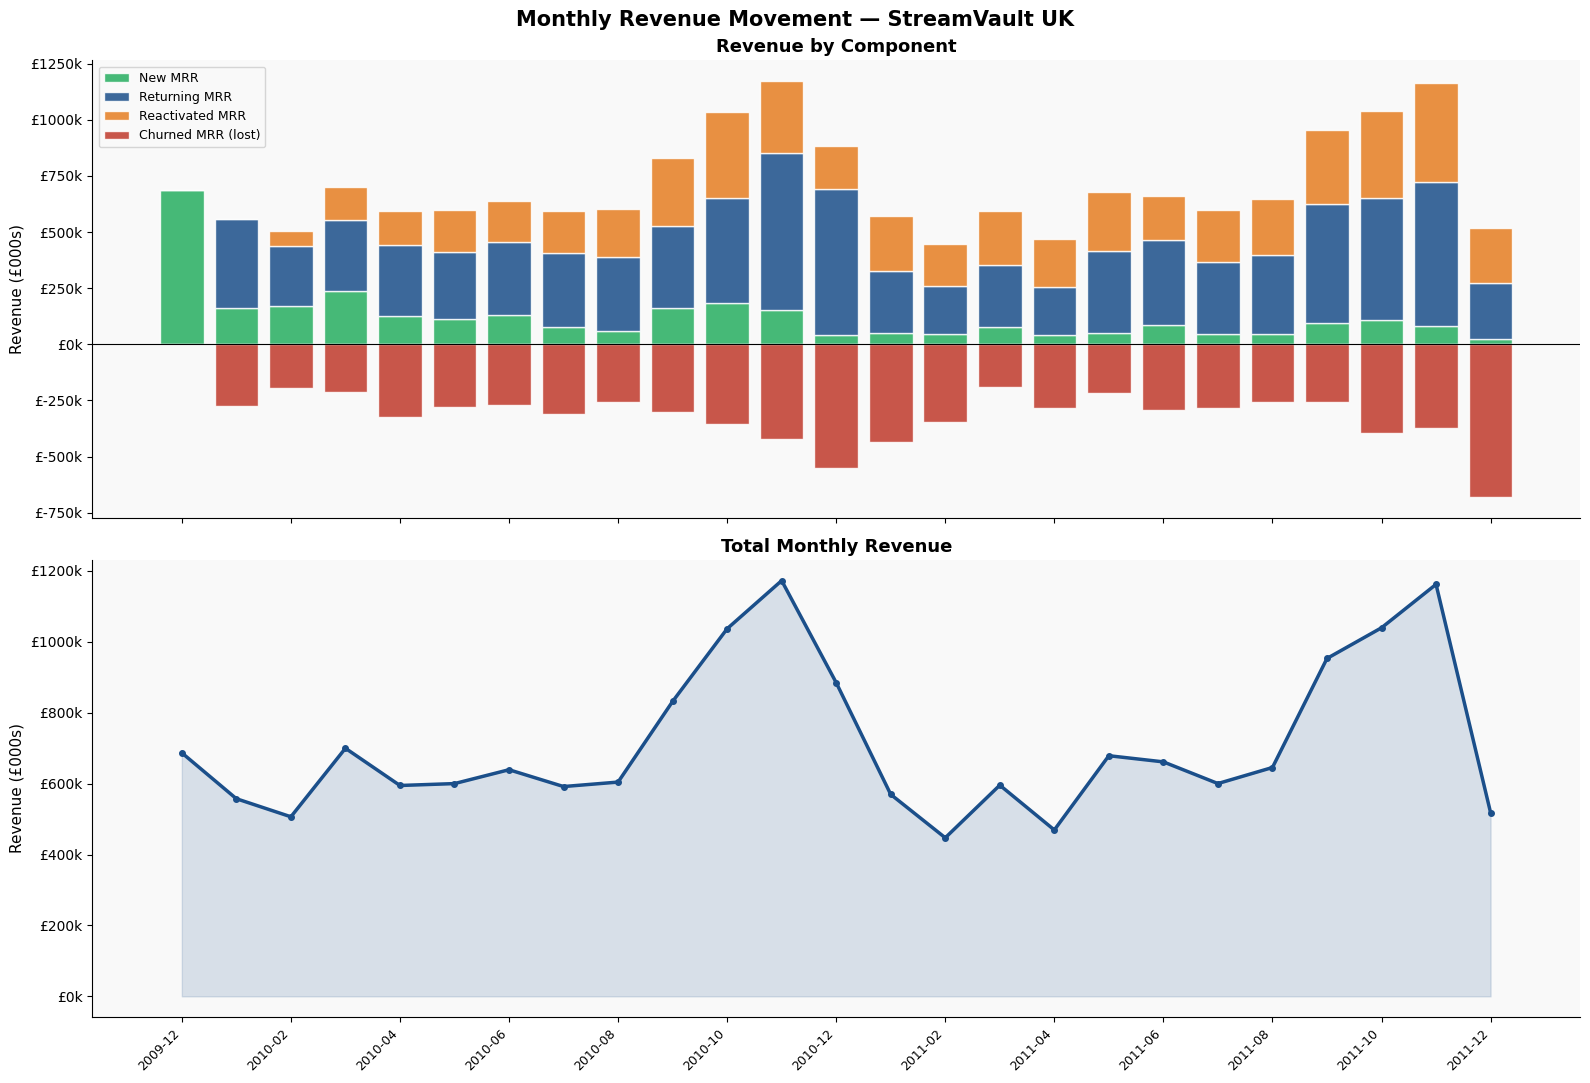

Business interpretation:
New MRR        = revenue from customers making their first-ever purchase
Returning MRR  = revenue from customers who also purchased last month
Reactivated MRR= revenue from lapsed customers who came back
Churned MRR    = revenue from last month's customers who did NOT return

Average monthly revenue churn rate : 45.0%
(This is revenue churn — different from subscriber churn in the Telco dataset)


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)
fig.suptitle('Monthly Revenue Movement — StreamVault UK', fontsize=15, fontweight='bold')

x = range(len(mrr_df))

# Top chart: stacked positive components + churned MRR below zero
axes[0].bar(x, mrr_df['New MRR'] / 1000,
            label='New MRR', color=GREEN, alpha=0.85, edgecolor='white')
axes[0].bar(x, mrr_df['Returning MRR'] / 1000,
            bottom=mrr_df['New MRR'] / 1000,
            label='Returning MRR', color=BLUE, alpha=0.85, edgecolor='white')
axes[0].bar(x, mrr_df['Reactivated MRR'] / 1000,
            bottom=(mrr_df['New MRR'] + mrr_df['Returning MRR']) / 1000,
            label='Reactivated MRR', color=ORANGE, alpha=0.85, edgecolor='white')
axes[0].bar(x, mrr_df['Churned MRR'] / 1000,
            label='Churned MRR (lost)', color=RED, alpha=0.85, edgecolor='white')
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('Revenue by Component', fontweight='bold')
axes[0].set_ylabel('Revenue (£000s)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:.0f}k'))
axes[0].legend(loc='upper left', fontsize=9)

# Bottom chart: total revenue line
axes[1].fill_between(x, mrr_df['Total Revenue'] / 1000, alpha=0.15, color=BLUE)
axes[1].plot(x, mrr_df['Total Revenue'] / 1000,
             color=BLUE, lw=2.5, marker='o', ms=4)
axes[1].set_title('Total Monthly Revenue', fontweight='bold')
axes[1].set_ylabel('Revenue (£000s)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:.0f}k'))

step = max(1, len(mrr_df) // 12)
axes[1].set_xticks(list(range(0, len(mrr_df), step)))
axes[1].set_xticklabels(mrr_df['Month'].iloc[::step], rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '12_mrr_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

print("Business interpretation:")
print("New MRR        = revenue from customers making their first-ever purchase")
print("Returning MRR  = revenue from customers who also purchased last month")
print("Reactivated MRR= revenue from lapsed customers who came back")
print("Churned MRR    = revenue from last month's customers who did NOT return")
print()
avg_churn_pct = (mrr_df['Churned MRR'].abs() / mrr_df['Total Revenue'].shift(1)).dropna().mean()
print(f"Average monthly revenue churn rate : {avg_churn_pct*100:.1f}%")
print("(This is revenue churn — different from subscriber churn in the Telco dataset)")


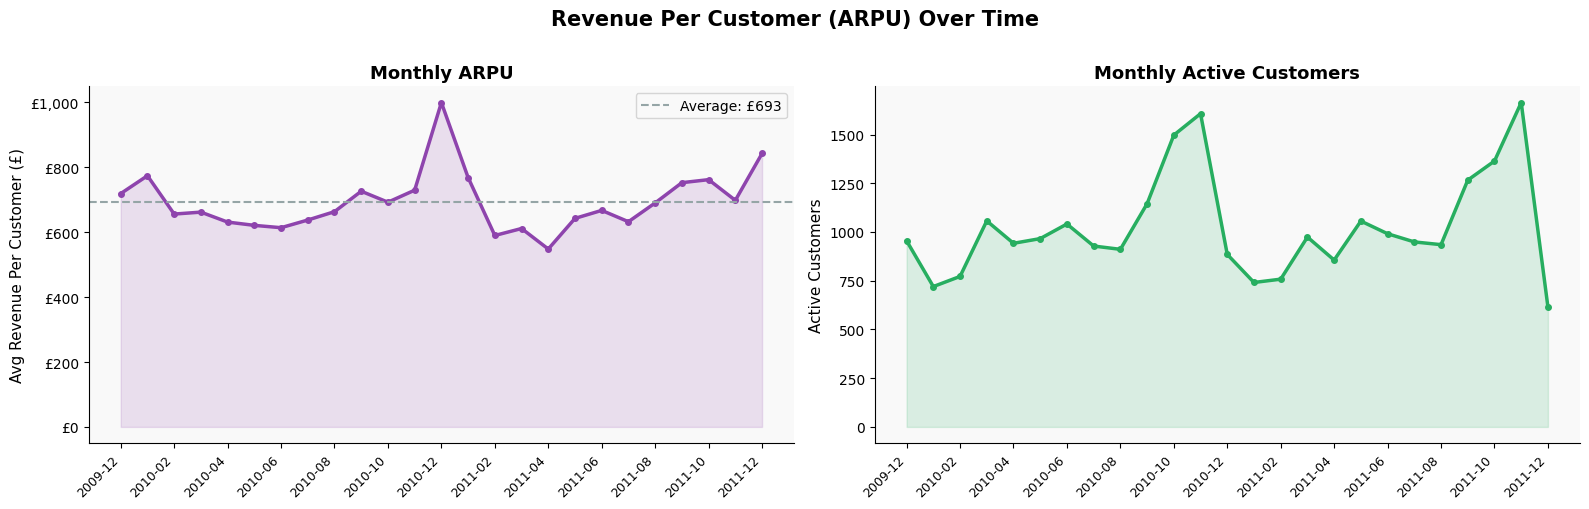

ARPU summary:
  Average ARPU : £693
  Peak ARPU    : £1,000  (2010-12)
  Lowest ARPU  : £548  (2011-04)


In [ ]:
mrr_df['ARPU'] = mrr_df['Total Revenue'] / mrr_df['Active Customers']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Revenue Per Customer (ARPU) Over Time', fontsize=15, fontweight='bold', y=1.01)

x = range(len(mrr_df))
step = max(1, len(mrr_df) // 12)

# Left: ARPU over time
axes[0].fill_between(x, mrr_df['ARPU'], alpha=0.15, color=PURPLE)
axes[0].plot(x, mrr_df['ARPU'], color=PURPLE, lw=2.5, marker='o', ms=4)
axes[0].axhline(mrr_df['ARPU'].mean(), color=GREY, linestyle='--', lw=1.5,
                label=f"Average: £{mrr_df['ARPU'].mean():,.0f}")
axes[0].set_title('Monthly ARPU', fontweight='bold')
axes[0].set_ylabel('Avg Revenue Per Customer (£)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
axes[0].set_xticks(list(range(0, len(mrr_df), step)))
axes[0].set_xticklabels(mrr_df['Month'].iloc[::step], rotation=45, ha='right', fontsize=9)
axes[0].legend()

# Right: Active customers over time
axes[1].fill_between(x, mrr_df['Active Customers'], alpha=0.15, color=GREEN)
axes[1].plot(x, mrr_df['Active Customers'], color=GREEN, lw=2.5, marker='o', ms=4)
axes[1].set_title('Monthly Active Customers', fontweight='bold')
axes[1].set_ylabel('Active Customers')
axes[1].set_xticks(list(range(0, len(mrr_df), step)))
axes[1].set_xticklabels(mrr_df['Month'].iloc[::step], rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '13_arpu_trend.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"ARPU summary:")
print(f"  Average ARPU : £{mrr_df['ARPU'].mean():,.0f}")
print(f"  Peak ARPU    : £{mrr_df['ARPU'].max():,.0f}  ({mrr_df.loc[mrr_df['ARPU'].idxmax(), 'Month']})")
print(f"  Lowest ARPU  : £{mrr_df['ARPU'].min():,.0f}  ({mrr_df.loc[mrr_df['ARPU'].idxmin(), 'Month']})")


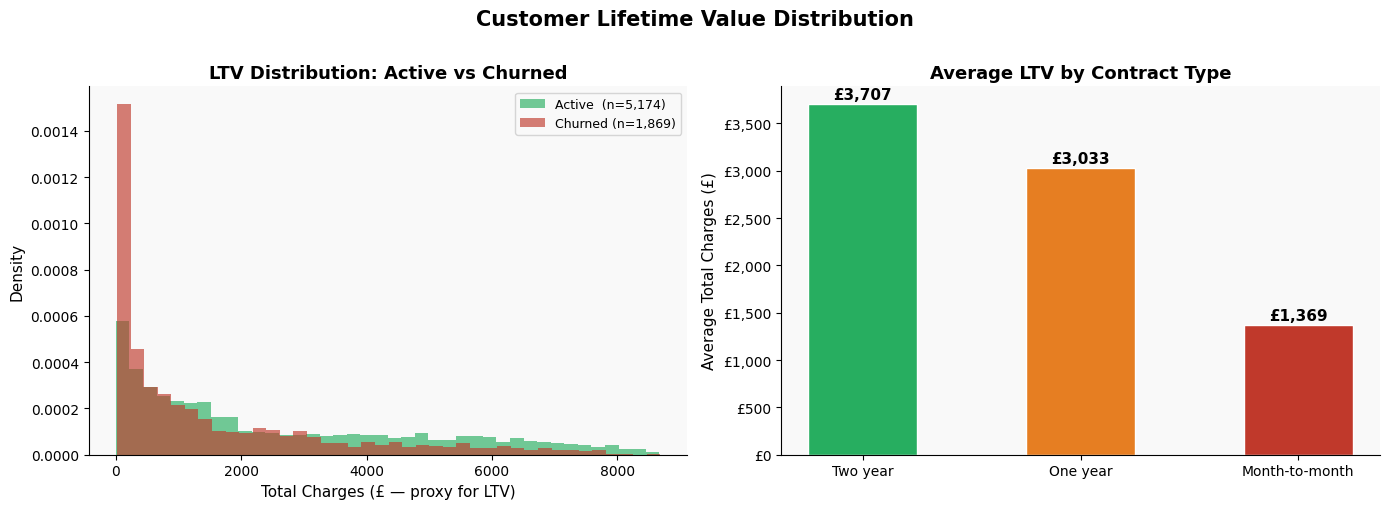

LTV summary (historical, from TotalCharges):
  Active subscribers  — avg LTV : £2,550
  Churned subscribers — avg LTV : £1,532

LTV by contract type:
  Two year             : £3,707
  One year             : £3,033
  Month-to-month       : £1,369


In [ ]:
active = df[df['Churn_Binary'] == 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Customer Lifetime Value Distribution', fontsize=15, fontweight='bold', y=1.01)

# Left: LTV histogram (active vs churned)
axes[0].hist(df[df['Churn_Binary'] == 0]['TotalCharges'], bins=40,
             alpha=0.65, color=GREEN, label=f"Active  (n={len(df[df['Churn_Binary']==0]):,})", density=True)
axes[0].hist(df[df['Churn_Binary'] == 1]['TotalCharges'], bins=40,
             alpha=0.65, color=RED,   label=f"Churned (n={len(df[df['Churn_Binary']==1]):,})", density=True)
axes[0].set_title('LTV Distribution: Active vs Churned', fontweight='bold')
axes[0].set_xlabel('Total Charges (£ — proxy for LTV)')
axes[0].set_ylabel('Density')
axes[0].legend(fontsize=9)

# Right: average LTV by contract type
ltv_contract = df.groupby('Contract')['TotalCharges'].mean().sort_values(ascending=False)
colors = [GREEN, ORANGE, RED]
bars = axes[1].bar(ltv_contract.index, ltv_contract.values,
                   color=colors, width=0.5, edgecolor='white')
axes[1].set_title('Average LTV by Contract Type', fontweight='bold')
axes[1].set_ylabel('Average Total Charges (£)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
for bar, val in zip(bars, ltv_contract.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20,
                 f'£{val:,.0f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '14_ltv_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("LTV summary (historical, from TotalCharges):")
print(f"  Active subscribers  — avg LTV : £{df[df['Churn_Binary']==0]['TotalCharges'].mean():,.0f}")
print(f"  Churned subscribers — avg LTV : £{df[df['Churn_Binary']==1]['TotalCharges'].mean():,.0f}")
print()
print("LTV by contract type:")
for ct, val in ltv_contract.items():
    print(f"  {ct:<20} : £{val:,.0f}")


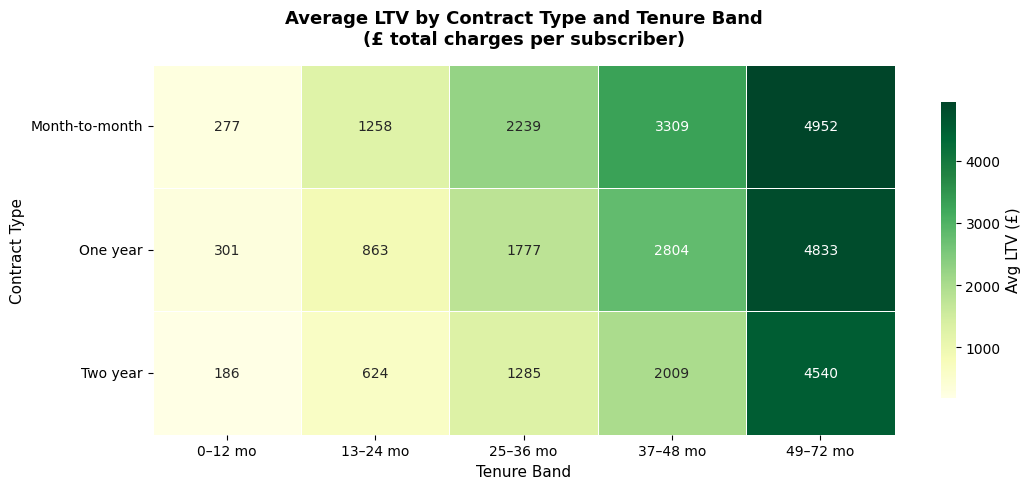

Business interpretation:
Two-year contract subscribers in the 49–72 month band are your highest-LTV customers.
The LTV gap between contract types grows wider with tenure.
This reinforces the case for annual contract conversion early in the lifecycle.


In [ ]:
bins_t   = [0, 12, 24, 36, 48, 72]
labels_t = ['0–12 mo', '13–24 mo', '25–36 mo', '37–48 mo', '49–72 mo']
df['TenureBand'] = pd.cut(df['tenure'], bins=bins_t, labels=labels_t, include_lowest=True)

# Average LTV by contract type AND tenure band
ltv_pivot = df.groupby(['Contract', 'TenureBand'], observed=True)['TotalCharges'].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    ltv_pivot,
    annot=True,
    fmt='.0f',
    cmap='YlGn',
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'label': 'Avg LTV (£)', 'shrink': 0.8},
    annot_kws={'size': 10},
)
ax.set_title('Average LTV by Contract Type and Tenure Band\n(£ total charges per subscriber)',
             fontweight='bold', pad=15)
ax.set_xlabel('Tenure Band')
ax.set_ylabel('Contract Type')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(FIGURES / '15_ltv_segmentation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("Business interpretation:")
print("Two-year contract subscribers in the 49–72 month band are your highest-LTV customers.")
print("The LTV gap between contract types grows wider with tenure.")
print("This reinforces the case for annual contract conversion early in the lifecycle.")


LTV by contract segment:

  Contract     : Month-to-month
  Subscribers  : 3,875
  Avg monthly  : £66.40
  Churn rate   : 42.7%
  Historical LTV (observed) : £1,369
  Predictive LTV (formula)  : £155

  Contract     : One year
  Subscribers  : 1,473
  Avg monthly  : £65.05
  Churn rate   : 11.3%
  Historical LTV (observed) : £3,033
  Predictive LTV (formula)  : £577

  Contract     : Two year
  Subscribers  : 1,695
  Avg monthly  : £60.77
  Churn rate   : 2.8%
  Historical LTV (observed) : £3,707
  Predictive LTV (formula)  : £2,146



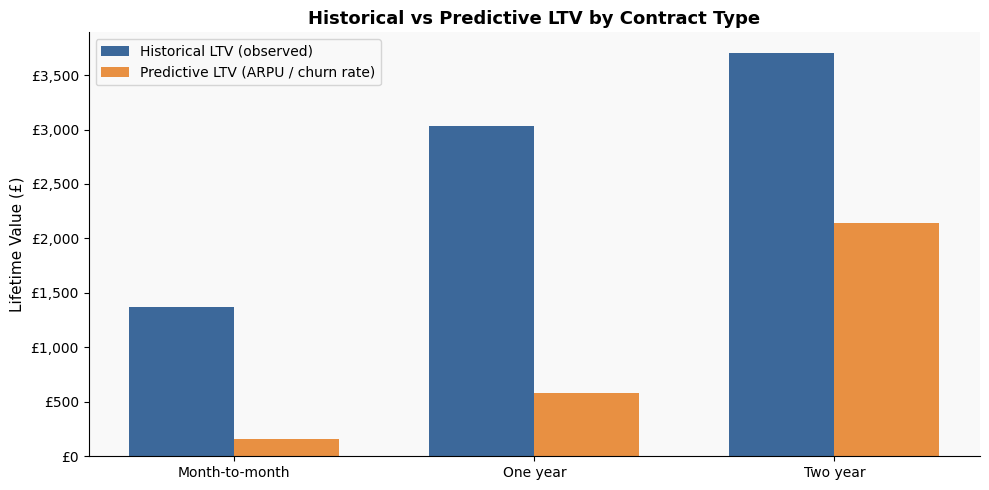

Interview talking point:
The predictive LTV formula (ARPU / churn rate) is derived from the geometric
series assumption — constant monthly churn probability. In practice, churn is
higher in early months (as we saw in the tenure analysis), so this formula
slightly overstates LTV for new subscribers and understates it for long-tenured ones.
A more precise approach uses survival analysis — that is covered in Notebook 04.


In [ ]:
# LTV formula for a subscription business:
# LTV = ARPU / Churn Rate
#
# Derivation: if a subscriber has a p% monthly churn probability, they are
# expected to stay for 1/p months on average (geometric distribution).
# Over those months they pay ARPU each month, so LTV = ARPU * (1/p) = ARPU / p.

segment_stats = (
    df.groupby('Contract')
    .agg(
        Subscribers    = ('customerID', 'count'),
        Avg_Monthly    = ('MonthlyCharges', 'mean'),
        Churn_Rate     = ('Churn_Binary', 'mean'),
        Historical_LTV = ('TotalCharges', 'mean'),
    )
    .reset_index()
)

# Predictive LTV = ARPU / monthly churn rate
segment_stats['Predictive_LTV'] = segment_stats['Avg_Monthly'] / segment_stats['Churn_Rate']

print("LTV by contract segment:")
print()
for _, row in segment_stats.iterrows():
    print(f"  Contract     : {row['Contract']}")
    print(f"  Subscribers  : {row['Subscribers']:,}")
    print(f"  Avg monthly  : £{row['Avg_Monthly']:.2f}")
    print(f"  Churn rate   : {row['Churn_Rate']*100:.1f}%")
    print(f"  Historical LTV (observed) : £{row['Historical_LTV']:,.0f}")
    print(f"  Predictive LTV (formula)  : £{row['Predictive_LTV']:,.0f}")
    print()

# Visualise
fig, ax = plt.subplots(figsize=(10, 5))
x       = range(len(segment_stats))
width   = 0.35
bars1   = ax.bar([i - width/2 for i in x], segment_stats['Historical_LTV'],
                 width=width, color=BLUE, alpha=0.85, label='Historical LTV (observed)')
bars2   = ax.bar([i + width/2 for i in x], segment_stats['Predictive_LTV'],
                 width=width, color=ORANGE, alpha=0.85, label='Predictive LTV (ARPU / churn rate)')
ax.set_title('Historical vs Predictive LTV by Contract Type', fontweight='bold')
ax.set_ylabel('Lifetime Value (£)')
ax.set_xticks(list(x))
ax.set_xticklabels(segment_stats['Contract'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))
ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / '16_predictive_ltv.png', dpi=150, bbox_inches='tight')
plt.show()

print("Interview talking point:")
print("The predictive LTV formula (ARPU / churn rate) is derived from the geometric")
print("series assumption — constant monthly churn probability. In practice, churn is")
print("higher in early months (as we saw in the tenure analysis), so this formula")
print("slightly overstates LTV for new subscribers and understates it for long-tenured ones.")
print("A more precise approach uses survival analysis — that is covered in Notebook 04.")


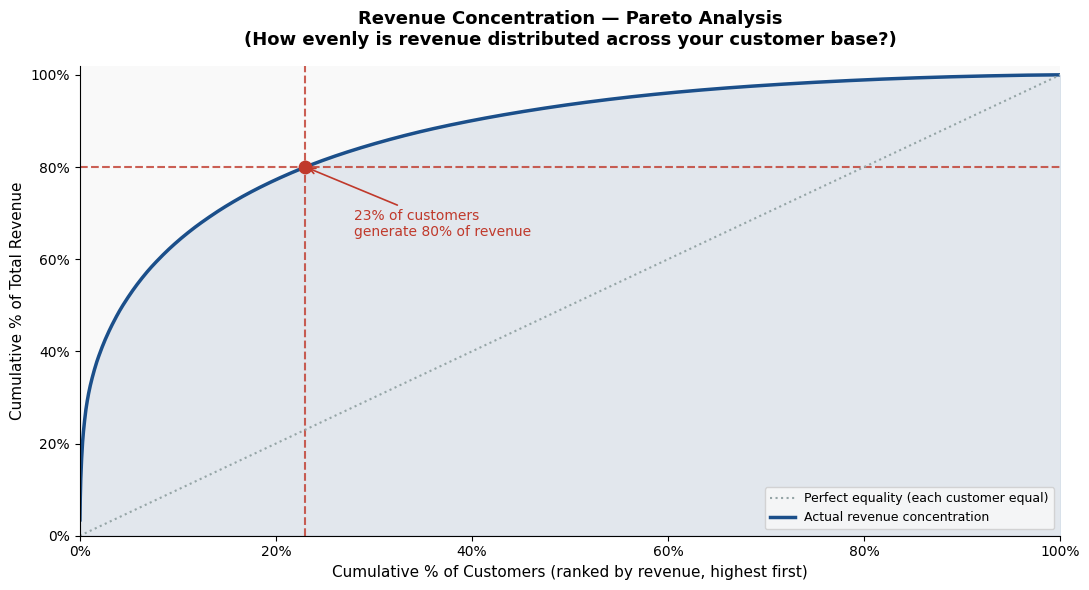

Revenue concentration findings:
  23% of customers generate 80% of total revenue
  Top 10% of customers generate 64% of total revenue

Business implication:
Retention investment should be weighted toward high-revenue customers.
Losing the top 10% of customers would cost 64% of revenue — churn risk scoring (Notebook 04) applied to
this segment has the highest financial return.


In [ ]:
# Which customers generate the most revenue? Classic 80/20 analysis.
# Using Online Retail II for this — it has actual revenue per customer.

customer_rev = (
    retail.groupby('Customer ID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
customer_rev['CumRevenue']    = customer_rev['Revenue'].cumsum()
customer_rev['CumRevenuePct'] = customer_rev['CumRevenue'] / customer_rev['Revenue'].sum() * 100
customer_rev['CustomerPct']   = (np.arange(1, len(customer_rev) + 1) / len(customer_rev)) * 100

# Find the 80% revenue threshold
threshold_80 = customer_rev[customer_rev['CumRevenuePct'] >= 80].iloc[0]
pct_customers_for_80 = threshold_80['CustomerPct']

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(customer_rev['CustomerPct'], customer_rev['CumRevenuePct'],
        color=BLUE, lw=2.5)
ax.fill_between(customer_rev['CustomerPct'], customer_rev['CumRevenuePct'],
                alpha=0.1, color=BLUE)

# Mark the 80% line
ax.axhline(80, color=RED, linestyle='--', lw=1.5, alpha=0.8)
ax.axvline(pct_customers_for_80, color=RED, linestyle='--', lw=1.5, alpha=0.8)
ax.scatter([pct_customers_for_80], [80], color=RED, s=80, zorder=5)
ax.annotate(
    f'{pct_customers_for_80:.0f}% of customers\ngenerate 80% of revenue',
    xy=(pct_customers_for_80, 80),
    xytext=(pct_customers_for_80 + 5, 65),
    fontsize=10, color=RED,
    arrowprops={'arrowstyle': '->', 'color': RED, 'lw': 1.2}
)

# Add the 45-degree equality line for reference
ax.plot([0, 100], [0, 100], color=GREY, linestyle=':', lw=1.5, label='Perfect equality (each customer equal)')
ax.plot([], [], color=BLUE, lw=2.5, label='Actual revenue concentration')

ax.set_title('Revenue Concentration — Pareto Analysis\n(How evenly is revenue distributed across your customer base?)',
             fontweight='bold', pad=15)
ax.set_xlabel('Cumulative % of Customers (ranked by revenue, highest first)')
ax.set_ylabel('Cumulative % of Total Revenue')
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '17_pareto_revenue.png', dpi=150, bbox_inches='tight')
plt.show()

top10_rev = customer_rev.head(int(len(customer_rev) * 0.10))['Revenue'].sum()
top10_pct = top10_rev / customer_rev['Revenue'].sum() * 100

print(f"Revenue concentration findings:")
print(f"  {pct_customers_for_80:.0f}% of customers generate 80% of total revenue")
print(f"  Top 10% of customers generate {top10_pct:.0f}% of total revenue")
print()
print("Business implication:")
print("Retention investment should be weighted toward high-revenue customers.")
print("Losing the top 10% of customers would cost", end=' ')
print(f"{top10_pct:.0f}% of revenue — churn risk scoring (Notebook 04) applied to")
print("this segment has the highest financial return.")
